# Lab 10: Community composition — Single Large or Several Small (SLOSS)?

### **This is an imaginary exercise.**

Suppose Maine can protect **1,000 km²** in one reserve or divide the same area
among three smaller reserves. Which strategy is better depends on how we
measure biodiversity and what we want to conserve.

This is the **SLOSS** question: **Single Large or Several Small**. We will use
imaginary reserves and real amphibian records to explore the
[week 10 topics](../schedule/week-10.md).

By the end of this lab you should be able to:

- calculate richness, Shannon diversity, and Simpson diversity;
- distinguish alpha, beta, and gamma diversity;
- calculate endemism and rarity metrics;
- explain how sampling affects a reserve comparison.

**Before beginning:**

- Would you prioritize total number of species (species richness), rare species (endemics), or areas with more even abundances per species?
- Given this, would you choose to protect one large (OL) reserve or several small (SS) reserves?
- What other advantages or disadvantages might the OL vs SS strategies have?

## 0. Install and import packages necessary packages

All the packages we are using today are things we have seen before.

We will also set a couple variables (`AREA_CRS` and `COLORS`) that we can use later
to make things a bit cleaner.

In [1]:
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Albers Equal Area Conic projection in units of meters
AREA_CRS = "EPSG:5070"

# Custom colors to make it pretty
COLORS = {"single_large": "#287c8e", 
          "several_small": "#b56b32"}

## 1. Load the data

[`ME_ImaginaryParks.geojson`](../data/ME_ImaginaryParks.geojson) contains four
imaginary parks and their occurrence records. Each point already has a park assignment.

| Imaginary park | Strategy | Area (km²) | Location |
| --- | --- | ---: | --- |
| Alder Basin Preserve | Single large | 1,000 | Central interior |
| Fern Hollow Woods | Several small | 400 | Southwest |
| Coldwater Ridge Preserve | Several small | 300 | Northern interior |
| Spruce Lantern Reserve | Several small | 300 | Eastern interior |

Run this notebook from `docs/labs` using the course Python environment.
See the [dataset notes](../data/ME_ImaginaryParks.md) for how the parks were made.

In [3]:
features = gpd.read_file("../data/ME_ImaginaryParks.geojson")
parks = features[features.feature_type == "park"].copy().to_crs(AREA_CRS).set_index("park_id")
records = features[features.feature_type == "occurrence"].copy().to_crs(AREA_CRS)

print("# of occurrence records: ", records.shape)

# Keep a list of the parks in order for later
park_order = list(parks.index)

parks.explore()

# of occurrence records:  (1500, 20)


## 2. Map the parks

Use the equal-area projection EPSG:5070 to measure area in square kilometers.
Both strategies protect 1,000 km².

scenario
several_small    1000.000809
single_large     1000.001413
Name: measured_km2, dtype: float64

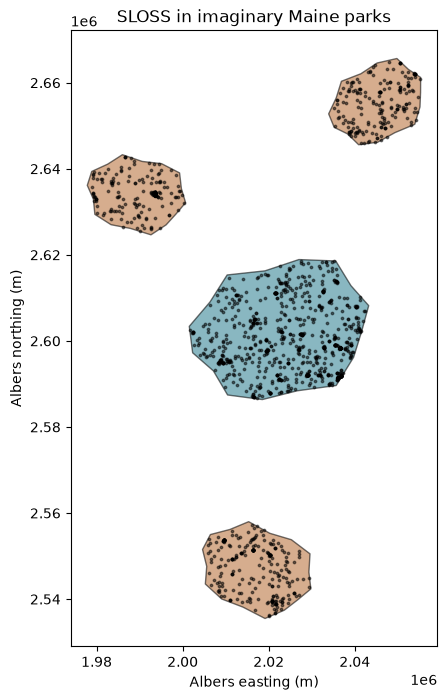

In [4]:
parks = parks.assign(measured_km2=parks.area / 1e6)

display(parks.groupby("scenario").measured_km2.sum())

fig, ax = plt.subplots(figsize=(8, 8))

#To plot ME boundary
#maine = gpd.read_file("ME_ShapeFiles/Maine_State_Boundary.shp").to_crs(AREA_CRS)
#maine.plot(ax=ax, color="#f1f0e9", edgecolor="#8c8c80", linewidth=0.5)

for strategy, group in parks.groupby("scenario"):
    group.plot(ax=ax, color=COLORS[strategy], alpha=0.55, edgecolor="black")

records.plot(ax=ax, color="black", markersize=3, alpha=0.5)

# Annotate parks by name
#for row in parks.itertuples():
#    anchor = row.geometry.representative_point()
#    ax.annotate(f"{row.Index}: {row.park_name}", (anchor.x, anchor.y),
#                xytext=(8, 10), textcoords="offset points", fontsize=8)

ax.set(title="SLOSS in imaginary Maine parks",
       xlabel="Albers easting (m)", ylabel="Albers northing (m)")
plt.show()

## 3. Build a community matrix

Our communities are the species **recorded in each park**. These are not comprehensive surveys,
there are problems with unequal sampling effort, but we will just go ahead with what we have.

In the **community matrix**, rows are parks, columns are species, and values
are record counts. Convert counts to presence/absence to compare species lists.

species,Ambystoma laterale,Ambystoma maculatum,Anaxyrus americanus,Aquarana clamitans,Aquarana septentrionalis,Boreorana sylvatica,Desmognathus fuscus,Dryophytes versicolor,Eurycea bislineata,Fictotriton alderi,...,Sylvophantoma glacialina,Sylvophantoma hazelii,Sylvophantoma inverna,Sylvophantoma kettleii,Sylvophantoma lichenosa,Sylvophantoma mapleii,Sylvophantoma noctiluca,Sylvophantoma sprucea,Sylvophantoma willowii,Sylvophantoma zephyra
park_id,,,,,,,,,,,,,,,,,,,,,
SL,1,33,82,61,0,96,1,37,2,0,...,1,0,0,3,10,5,0,0,1,10
SS1,0,6,25,22,0,15,0,9,0,0,...,0,0,0,3,2,4,1,0,0,4
SS2,1,8,13,16,0,12,0,7,3,0,...,0,1,1,1,1,4,1,1,0,5
SS3,0,11,29,14,1,18,0,11,1,1,...,0,0,0,3,3,0,0,1,1,1


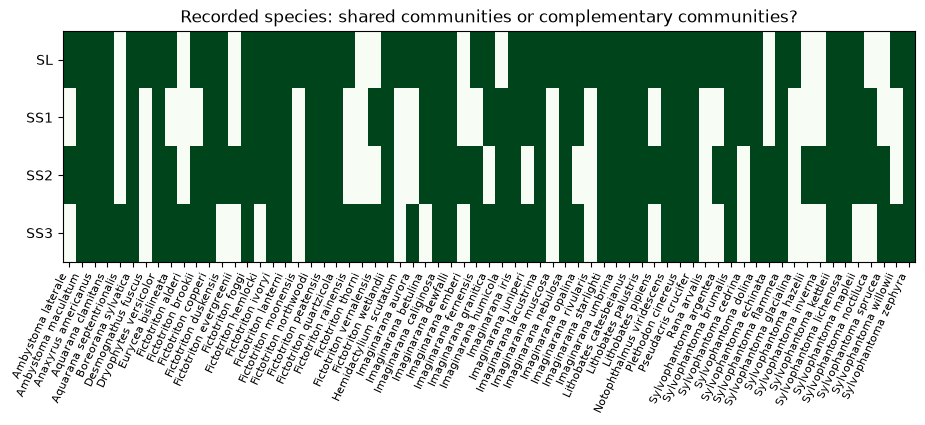

In [5]:
community = pd.crosstab(records.park_id, records.species).reindex(park_order, fill_value=0)

#community.loc["SS"] = community.iloc[1:, :].sum(axis=0)
presence = community.gt(0)
display(community)

fig, ax = plt.subplots(figsize=(11, 3))
image = ax.imshow(presence.astype(int), aspect="auto", cmap="Greens", vmin=0, vmax=1)
ax.set(yticks=range(len(community)), yticklabels=community.index,
       xticks=range(len(community.columns)), xticklabels=community.columns,
       title="Recorded species: shared communities or complementary communities?")
plt.setp(ax.get_xticklabels(), rotation=65, ha="right", fontsize=8)
plt.show()

## 4. Richness and Shannon diversity

**Richness** is the number of species recorded. **Shannon diversity** also
accounts for how evenly records are distributed among species:
$H' = -\sum_i p_i\ln p_i$.

SciPy's [`entropy`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.entropy.html)
calculates Shannon diversity directly from counts, converting them to proportions
and using natural logs. Compare two communities with the same richness:

In [8]:
from scipy.stats import entropy
from scipy.spatial.distance import jaccard

print("Even community:", entropy([10, 10, 10]))
print("Dominated community:", entropy([28, 1, 1]))

Even community: 1.0986122886681096
Dominated community: 0.29113983883196504


Now calculate both measures for each park. In the loop, `counts` is one row
of the community matrix. `counts[counts > 0]` keeps the species recorded there.
We will reuse this function for other community matrices. Units without records
have missing diversity values (`NaN`).

In [9]:
def diversity(community_counts):
    results = pd.DataFrame(
        index=community_counts.index,
        columns=["n_records", "richness", "shannon"],
        dtype=float,
    )
    for unit, counts in community_counts.iterrows():
        species_present = counts[counts > 0]
        results.loc[unit, "n_records"] = counts.sum()
        if len(species_present) == 0:
            continue
        results.loc[unit, "richness"] = len(species_present)
        results.loc[unit, "shannon"] = entropy(species_present)
    return results

park_metrics = diversity(community)
park_metrics["evenness"] = np.exp(park_metrics["shannon"])/park_metrics["richness"]
park_metrics["park_name"] = parks.park_name
park_metrics["scenario"] = parks.scenario
display(park_metrics)

,n_records,richness,shannon,evenness,park_name,scenario
park_id,,,,,,
SL,819.0,55.0,3.207115,0.449231,Alder Basin Preserve,single_large
SS1,252.0,42.0,3.295661,0.642744,Fern Hollow Woods,several_small
SS2,192.0,49.0,3.438732,0.635662,Coldwater Ridge Preserve,several_small
SS3,237.0,47.0,3.227652,0.536603,Spruce Lantern Reserve,several_small


Does the richest park also have the highest Shannon diversity? What would
100 additional bullfrog records change? These indices describe the records;
record frequencies are not animal abundances.

## 5. Alpha, beta, and gamma diversity

- **Alpha:** mean park richness within a strategy.
- **Gamma:** pooled richness across that strategy, counting each species once.
- **Multiplicative beta:** $\gamma/\bar\alpha$.

First pool the record counts for all parks belonging to each strategy.

In [10]:
strategies = ["single_large", "several_small"]
strategy_counts = pd.DataFrame(
    index=strategies, columns=community.columns, dtype=float
)
for strategy in strategies:
    park_ids = parks[parks.scenario == strategy].index
    strategy_counts.loc[strategy] = community.loc[park_ids].sum()

strategy_metrics = diversity(strategy_counts)
strategy_metrics = strategy_metrics.rename(columns={"richness": "gamma_richness"})
for strategy in strategies:
    local_parks = park_metrics[park_metrics.scenario == strategy]
    alpha = local_parks.richness.mean()
    gamma = strategy_metrics.loc[strategy, "gamma_richness"]
    strategy_metrics.loc[strategy, "mean_park_alpha"] = alpha
    strategy_metrics.loc[strategy, "beta_ratio"] = gamma / alpha
    strategy_metrics.loc[strategy, "sum_park_richness"] = local_parks.richness.sum()
    strategy_metrics.loc[strategy, "area_km2"] = parks[parks.scenario == strategy].measured_km2.sum()
display(strategy_metrics)

,n_records,gamma_richness,shannon,mean_park_alpha,beta_ratio,sum_park_richness,area_km2
single_large,819.0,55.0,3.207115,55.0,1.000000,55.0,1000.001413
several_small,681.0,60.0,3.419708,46.0,1.304348,138.0,1000.000809


Shared species explain why pooled richness can be smaller than the sum of
park richnesses. Which species does each strategy contribute?

In [11]:
single_counts = strategy_counts.loc["single_large"]
small_counts = strategy_counts.loc["several_small"]
single_species = set(single_counts[single_counts > 0].index)
small_species = set(small_counts[small_counts > 0].index)

print("Only in the large park:", sorted(single_species - small_species))
print("Only in the small parks:", sorted(small_species - single_species))
print("In both strategies:", len(single_species & small_species))

Only in the large park: ['Desmognathus fuscus', 'Fictotriton moonensis', 'Hemidactylium scutatum', 'Imaginarana muscosa', 'Imaginarana rivularis', 'Rana arvalis', 'Sylvophantoma glacialina']
Only in the small parks: ['Aquarana septentrionalis', 'Fictotriton alderi', 'Fictotriton evergreenii', 'Fictotriton thorni', 'Fictotriton vernalensis', 'Imaginarana emberi', 'Imaginarana humicola', 'Sylvophantoma echinata', 'Sylvophantoma hazelii', 'Sylvophantoma inverna', 'Sylvophantoma noctiluca', 'Sylvophantoma sprucea']
In both strategies: 48


Beta equals 1 for identical species lists and increases with differences among
parks. For a single park it is necessarily 1. Park areas also differ, so park-level alpha compares unequal areas.

### Jaccard dissimilarity

Jaccard compares species lists: $1 - |A\cap B|/|A\cup B|$.
Zero means identical lists; one means no shared species. Use **presence/absence**,
rather than record counts, with SciPy's
[`jaccard`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.jaccard.html).

In [12]:
print("SL versus SS1:", jaccard(presence.loc["SL"], presence.loc["SS1"]))

jaccard_distances = pd.DataFrame(index=park_order, columns=park_order, dtype=float)
for park_a in park_order:
    for park_b in park_order:
        jaccard_distances.loc[park_a, park_b] = jaccard(
            presence.loc[park_a], presence.loc[park_b]
        )
display(jaccard_distances.round(2))

SL versus SS1: 0.3275862068965517


,SL,SS1,SS2,SS3
SL,0.00,0.33,0.35,0.35
SS1,0.33,0.00,0.31,0.32
SS2,0.35,0.31,0.00,0.37
SS3,0.35,0.32,0.37,0.00


Which two parks are most different? Does that reflect species replacement,
a difference in richness, or both?

### Bray–Curtis dissimilarity

Jaccard uses presence/absence. **Bray–Curtis uses record counts**, so it also
responds to differences in how common each species is in the records:

$BC = \sum_i |a_i-b_i| / \sum_i(a_i+b_i)$.

Zero means identical count vectors; one means no shared species. Use SciPy's
[`braycurtis`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.braycurtis.html)
with rows of the count matrix.

In [13]:
from scipy.spatial.distance import braycurtis

print("SL versus SS1:", braycurtis(community.loc["SL"], community.loc["SS1"]))

bray_curtis_distances = pd.DataFrame(index=park_order, columns=park_order, dtype=float)
for park_a in park_order:
    for park_b in park_order:
        bray_curtis_distances.loc[park_a, park_b] = braycurtis(
            community.loc[park_a], community.loc[park_b]
        )
display(bray_curtis_distances.round(2))

SL versus SS1: 0.5462184873949579


,SL,SS1,SS2,SS3
SL,0.00,0.55,0.64,0.57
SS1,0.55,0.00,0.27,0.26
SS2,0.64,0.27,0.00,0.33
SS3,0.57,0.26,0.33,0.00


Unequal record totals also affect Bray–Curtis. To compare **relative species
frequencies**, divide each park's counts by its total before calculating the
distance. This adjusts totals but does not remove reporting bias.

In [14]:
a_counts = community.loc["SL"]
b_counts = community.loc["SS1"]
a_frequencies = a_counts / a_counts.sum()
b_frequencies = b_counts / b_counts.sum()
print("SL versus SS1, relative frequencies:", braycurtis(a_frequencies, b_frequencies))

SL versus SS1, relative frequencies: 0.19261294261294265


Do Jaccard and Bray–Curtis identify the same pair of parks as most different?
What information does each comparison use?

## 6. Compare equal numbers of records

Draw the same number of records from each strategy without replacement and
repeat 300 times. This **record-based rarefaction** checks sensitivity to sampling effort. 
The 2.5% and 97.5% quantiles describe the repeated draws, not confidence limits for true richness.

In [15]:
equal_n = records.groupby("scenario").size().min()
rarefaction = pd.DataFrame()
for strategy in strategies:
    strategy_records = records[records.scenario == strategy]
    richness_samples = []
    for repeat in range(300):
        sample = strategy_records.sample(n=equal_n, replace=True, random_state=repeat)
        richness_samples.append(sample.species.nunique())
    rarefaction.loc[strategy, "records_drawn"] = equal_n
    rarefaction.loc[strategy, "mean_richness"] = np.mean(richness_samples)
    rarefaction.loc[strategy, "q025"] = np.quantile(richness_samples, 0.025)
    rarefaction.loc[strategy, "q975"] = np.quantile(richness_samples, 0.975)
display(rarefaction)

,records_drawn,mean_richness,q025,q975
single_large,681.0,49.853333,46.475,53.0
several_small,681.0,54.556667,51.000,58.0


## 7. Endemism and rarity

**Endemism** means geographic restriction. Here we measure restriction within
the four-park sample, which cannot establish a species' full geographic range.

Let $r_i$ be the number of parks recording species $i$.

| Metric | Calculation |
| --- | --- |
| Sample-exclusive richness | Number of species with $r_i=1$ |
| Weighted endemism (WE) proxy | Sum of $1/r_i$ for species present |
| Corrected WE (CWE) proxy | WE divided by richness |

WE reflects richness and restriction; CWE measures average restriction.
Define **record-rare** species as those with at most five records across all
four parks. Low reporting need not mean a small population or a narrow range.

In [16]:
species_context = pd.DataFrame()
for species in community.columns:
    counts = community[species]
    species_context.loc[species, "n_records"] = counts.sum()
    species_context.loc[species, "parks_recorded"] = sum(counts > 0)
display(species_context)

rare_rows = species_context[species_context.n_records <= 5]
rare_species = list(rare_rows.index)
print("Record-rare species:", rare_species)

,n_records,parks_recorded
Ambystoma laterale,2.0,2.0
Ambystoma maculatum,58.0,4.0
Anaxyrus americanus,149.0,4.0
Aquarana clamitans,113.0,4.0
Aquarana septentrionalis,1.0,1.0
...,...,...
Sylvophantoma mapleii,13.0,3.0
Sylvophantoma noctiluca,2.0,2.0
Sylvophantoma sprucea,2.0,2.0
Sylvophantoma willowii,2.0,2.0


Record-rare species: ['Ambystoma laterale', 'Aquarana septentrionalis', 'Desmognathus fuscus', 'Fictotriton alderi', 'Fictotriton brookii', 'Fictotriton evergreenii', 'Fictotriton moonensis', 'Fictotriton rainensis', 'Fictotriton thorni', 'Fictotriton vernalensis', 'Hemidactylium scutatum', 'Imaginarana aurora', 'Imaginarana emberi', 'Imaginarana fernensis', 'Imaginarana granitica', 'Imaginarana humicola', 'Imaginarana muscosa', 'Imaginarana rivularis', 'Lithobates pipiens', 'Rana arvalis', 'Sylvophantoma argentea', 'Sylvophantoma cedrina', 'Sylvophantoma echinata', 'Sylvophantoma glacialina', 'Sylvophantoma hazelii', 'Sylvophantoma inverna', 'Sylvophantoma noctiluca', 'Sylvophantoma sprucea', 'Sylvophantoma willowii']


The next function visits each species recorded in a community. Add its inverse
occupancy to WE, then count whether it is exclusive or record-rare.

In [17]:
def restriction_metrics(community_counts):
    occupancy = (community_counts > 0).sum(axis=0)
    results = pd.DataFrame(
        index=community_counts.index,
        columns=["sample_exclusive", "we_proxy", "cwe_proxy", "record_rare_richness"],
        dtype=float,
    )
    for unit, counts in community_counts.iterrows():
        species_here = counts[counts > 0].index
        if len(species_here) == 0:
            continue
        exclusive = 0
        rare = 0
        weighted_endemism = 0
        for species in species_here:
            occupied_units = occupancy[species]
            weighted_endemism += 1 / occupied_units
            if occupied_units == 1:
                exclusive += 1
            if species in rare_species:
                rare += 1
        results.loc[unit, "sample_exclusive"] = exclusive
        results.loc[unit, "we_proxy"] = weighted_endemism
        results.loc[unit, "cwe_proxy"] = weighted_endemism / len(species_here)
        results.loc[unit, "record_rare_richness"] = rare
    return results

park_restriction = restriction_metrics(community)
display(park_metrics.join(park_restriction))

,n_records,richness,shannon,evenness,park_name,scenario,sample_exclusive,we_proxy,cwe_proxy,record_rare_richness
park_id,,,,,,,,,,
SL,819.0,55.0,3.207115,0.449231,Alder Basin Preserve,single_large,7.0,21.583333,0.392424,17.0
SS1,252.0,42.0,3.295661,0.642744,Fern Hollow Woods,several_small,0.0,11.916667,0.283730,5.0
SS2,192.0,49.0,3.438732,0.635662,Coldwater Ridge Preserve,several_small,4.0,17.416667,0.355442,13.0
SS3,237.0,47.0,3.227652,0.536603,Spruce Lantern Reserve,several_small,3.0,16.083333,0.342199,13.0


Which species are park-exclusive but not record-rare? How would records outside
these parks change your interpretation of endemism? Unequal park areas also
affect the occupancy comparison.

## 8. Export results

Save park and species summary tables to `outputs/Lab10`.

In [ ]:
output_dir = Path("outputs/Lab10")
output_dir.mkdir(parents=True, exist_ok=True)

park_metrics.join(park_restriction).to_csv(output_dir / "park_metrics.csv")

jaccard_distances.to_csv(output_dir / "park_jaccard.csv")
bray_curtis_distances.to_csv(output_dir / "park_bray_curtis.csv")

## Assignment: recommend a reserve strategy

Submit the completed notebook, park and species summary tables, and a
**400–600 word** interpretation addressing:

1. Your recommendation, using pooled richness, another metric, and rarefaction.
2. Alpha, beta, gamma, and species complementarity in your results.
3. Differences among WE, CWE, and record rarity, including their reference extent.
4. Differences between Jaccard and Bray–Curtis, and what each metric measures.
5. Sampling bias and missing records.

**Extension:** change the rarity threshold, year range, or coordinate-uncertainty
cutoff and compare your recommendation.

What additional evidence about habitat, connectivity, or population viability
would you need for a real SLOSS decision?